In [ ]:
# Experiment 1: AI Chatbot for Engineering College Queries

!pip install -q torch transformers

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

model_name = "Qwen/Qwen2.5-0.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype="auto"
)

college_info = """
Our college offers CSE, ECE, EEE and Mechanical Engineering.
College timings are 9 AM to 4 PM.
Library timings are 9 AM to 5 PM.
Students can contact the examination cell for exam queries.
"""

print("ENGINEERING COLLEGE CHATBOT")
print("Type exit to stop.\n")

while True:

    question = input("Ask your question: ")

    if question.lower() == "exit":
        print("Thank you!")
        break

    messages = [
        {
            "role": "system",
            "content": "Answer student questions using only the following college information. If information is missing, say so. " + college_info
        },
        {
            "role": "user",
            "content": question
        }
    ]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(text, return_tensors="pt")

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=100
        )

    response = tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

    print("Chatbot:", response)
    print()

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

ENGINEERING COLLEGE CHATBOT
Type exit to stop.

Ask your question: what are colleg timings
Chatbot: The college has the following timings:

- **CSE (Computer Science and Engineering)**: 9 AM to 4 PM
- **EEE (Electrical and Electronics Engineering)**: 9 AM to 4 PM
- **EEE (Electronic Engineering and Electrical Engineering)**: 9 AM to 4 PM

So, the college operates from 9 AM to 4 PM every day.

Ask your question: exit
Thank you!


In [ ]:
# Experiment 2: Engineering Support Chatbot Using NLP

!pip install -q transformers torch

from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

model_name = "Qwen/Qwen2.5-0.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(model_name)

print("ENGINEERING SUPPORT CHATBOT")

while True:
    question = input("Enter engineering question (exit to stop): ")

    if question.lower() == "exit":
        break

    messages = [
        {"role": "system", "content": "You are an engineering expert. Explain technical concepts simply and provide step-by-step solutions."},
        {"role": "user", "content": question}
    ]

    text = tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )

    inputs = tokenizer(text, return_tensors="pt")

    with torch.no_grad():
        outputs = model.generate(**inputs, max_new_tokens=150)

    answer = tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

    print("Solution:", answer)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

ENGINEERING SUPPORT CHATBOT
Enter engineering question (exit to stop): explain concepts easily
Solution: Certainly! Let's break down some complex concepts into simple, easy-to-understand steps:

### 1. **What is a Computer?**
   - A computer is a device that can store data, process information, and perform calculations.
   - It has hardware components like the CPU (Central Processing Unit), memory, input/output devices, and storage.

### 2. **Hardware Components of a Computer:**
   - **CPU:** Central Processing Unit, which performs all operations on data.
   - **Memory:** Temporary storage for data to be processed.
   - **Input/Output Devices:** These allow you to interact with computers using various methods:
     - Keyboard for typing commands or text.
     - Mouse for pointing and clicking.
     -
Enter engineering question (exit to stop): exit


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gtts 2.5.4 requires click<8.2,>=7.1, but you have click 8.5.1 which is incompatible.


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Enter image description: a bridge


  0%|          | 0/2 [00:00<?, ?it/s]

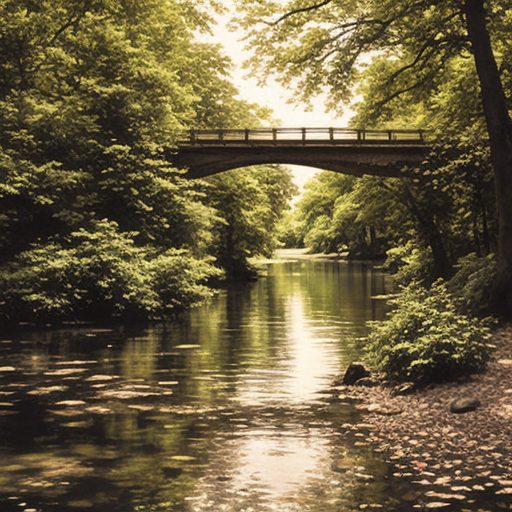

In [ ]:
# Experiment 3: Engineering Image Generation Using Text-to-Image Model

!pip install -q diffusers transformers accelerate

import torch
from diffusers import AutoPipelineForText2Image
from IPython.display import display

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32

pipe = AutoPipelineForText2Image.from_pretrained(
    "stabilityai/sd-turbo",
    torch_dtype=dtype
).to(device)

prompt = input("Enter image description: ")

image = pipe(
    prompt,
    num_inference_steps=2,
    guidance_scale=0.0
).images[0]

display(image)

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Prompt: A modern suspension bridge over a river


  0%|          | 0/2 [00:00<?, ?it/s]

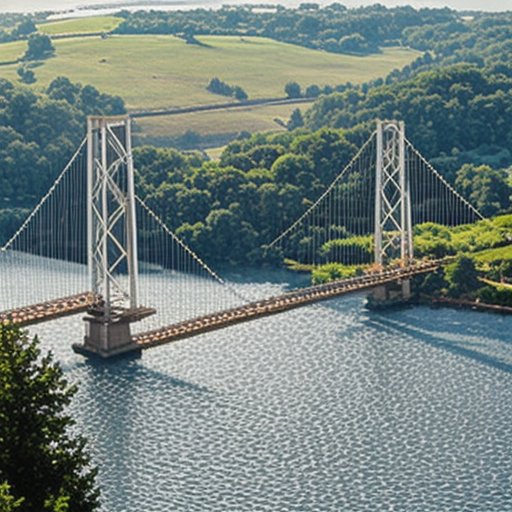

Prompt: A futuristic robotic arm in a factory


  0%|          | 0/2 [00:00<?, ?it/s]

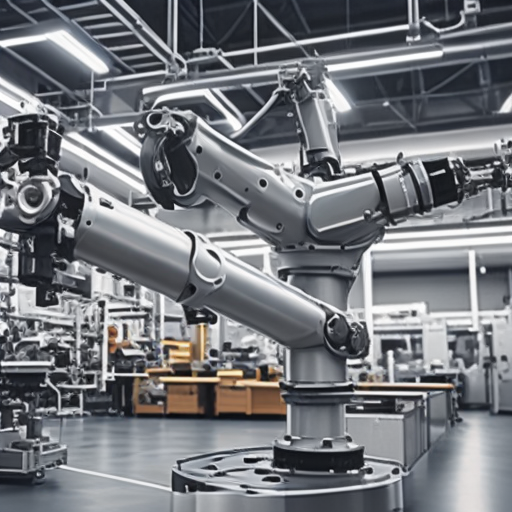

Prompt: A smart electric vehicle in a modern city


  0%|          | 0/2 [00:00<?, ?it/s]

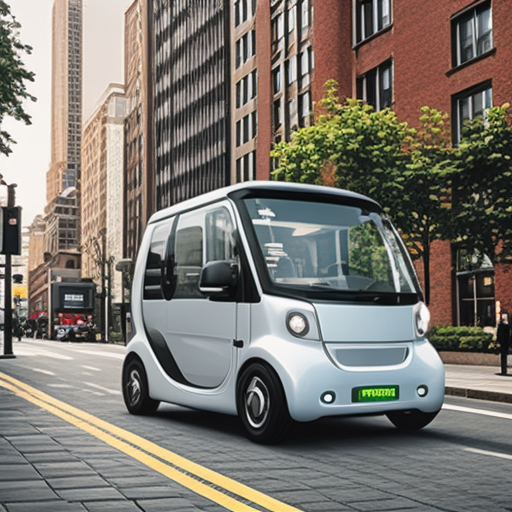

In [ ]:
# Experiment 4: Image Generation and Comparison Using Different Text Prompts

!pip install -q diffusers transformers accelerate

import torch
from diffusers import AutoPipelineForText2Image
from IPython.display import display

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32

pipe = AutoPipelineForText2Image.from_pretrained(
    "stabilityai/sd-turbo",
    torch_dtype=dtype
).to(device)

prompts = [
    "A modern suspension bridge over a river",
    "A futuristic robotic arm in a factory",
    "A smart electric vehicle in a modern city"
]

for prompt in prompts:
    print("Prompt:", prompt)

    image = pipe(
        prompt,
        num_inference_steps=2,
        guidance_scale=0.0
    ).images[0]

    display(image)

In [ ]:
# Experiment 5: Speech-to-Text Conversion Using Whisper Model

!pip install -q openai-whisper

import whisper
from google.colab import files

model = whisper.load_model("base")

uploaded = files.upload()

audio_file = list(uploaded.keys())[0]

result = model.transcribe(audio_file)

print("Recognized Speech:")
print(result["text"])

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


100%|████████████████████████████████████████| 139M/139M [00:01<00:00, 143MiB/s]


In [ ]:
# Experiment 6: Text-to-Speech Conversion Using gTTS

!pip install -q gTTS

from gtts import gTTS
from IPython.display import Audio, display

text = input("Enter engineering text: ")

speech = gTTS(text=text, lang="en")

speech.save("engineering_audio.mp3")

print("Audio generated successfully!")

display(Audio("engineering_audio.mp3"))

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
spacy 3.8.18 requires click<9.0.0,>=8.2.1, but you have click 8.1.8 which is incompatible.
wandb 0.28.1 requires click>=8.2.0, but you have click 8.1.8 which is incompatible.
huggingface-hub 1.33.0 requires click<9.0.0,>=8.4.2, but you have click 8.1.8 which is incompatible.
Enter engineering text: hello.
Audio generated successfully!


In [ ]:
# Experiment 7: Engineering Document Summarization Using Pretrained Language Model

!pip install -q transformers torch

from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

model_name = "Qwen/Qwen2.5-0.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(model_name)

document = """
Artificial Intelligence is widely used in engineering applications.
Machine learning helps engineers analyze data and predict system performance.
Robotics improves automation in manufacturing industries.
Computer vision is used for object detection and quality inspection.
AI technologies improve efficiency, accuracy and productivity.
"""

messages = [
    {
        "role": "system",
        "content": "You are a document summarization assistant. Summarize text in simple words."
    },
    {
        "role": "user",
        "content": "Summarize the following engineering document:\n" + document
    }
]

text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

inputs = tokenizer(text, return_tensors="pt")

with torch.no_grad():
    outputs = model.generate(
        **inputs,
        max_new_tokens=100
    )

summary = tokenizer.decode(
    outputs[0][inputs["input_ids"].shape[1]:],
    skip_special_tokens=True
)

print("Summary:")
print(summary)

In [ ]:
# Experiment 8: English to Hindi Translation Using Pretrained Language Model

!pip install -q transformers sentencepiece

from transformers import MarianMTModel, MarianTokenizer

model_name = "Helsinki-NLP/opus-mt-en-hi"

tokenizer = MarianTokenizer.from_pretrained(model_name)
model = MarianMTModel.from_pretrained(model_name)

text = input("Enter English engineering text: ")

tokens = tokenizer(text, return_tensors="pt", padding=True)

translated = model.generate(**tokens, max_new_tokens=150)

result = tokenizer.decode(
    translated[0],
    skip_special_tokens=True
)

print("Hindi Translation:")
print(result)

In [ ]:
# Experiment 9: AI-Based Resume Screening and Ranking Using NLP

!pip install -q scikit-learn

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

job_description = """
Looking for a software engineer skilled in Python, Java,
SQL, Machine Learning, Data Structures and Web Development.
"""

resumes = {
    "Candidate 1": "Python Java SQL machine learning and web development",
    "Candidate 2": "HTML CSS JavaScript frontend development",
    "Candidate 3": "Python Java data structures SQL and machine learning"
}

documents = [job_description] + list(resumes.values())

vectorizer = TfidfVectorizer()

vectors = vectorizer.fit_transform(documents)

scores = cosine_similarity(
    vectors[0:1],
    vectors[1:]
).flatten()

ranking = sorted(
    zip(resumes.keys(), scores),
    key=lambda x: x[1],
    reverse=True
)

print("RESUME SCREENING RESULTS\n")

for name, score in ranking:
    print(name, ":", round(score * 100, 2), "% match")

In [ ]:
# Experiment 10: AI-Based Research Assistance Using Pretrained Language Model

!pip install -q transformers torch

from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

model_name = "Qwen/Qwen2.5-0.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(model_name)

topic = input("Enter research topic: ")

messages = [
    {
        "role": "system",
        "content": "You are an engineering research assistant. Provide simple and useful research information."
    },
    {
        "role": "user",
        "content": f"""
        Research Topic: {topic}

        Provide:
        1. Introduction
        2. Important information
        3. Five research keywords
        4. A concise summary
        """
    }
]

text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

inputs = tokenizer(text, return_tensors="pt")

with torch.no_grad():
    outputs = model.generate(
        **inputs,
        max_new_tokens=200
    )

answer = tokenizer.decode(
    outputs[0][inputs["input_ids"].shape[1]:],
    skip_special_tokens=True
)

print("RESEARCH ASSISTANCE OUTPUT:")
print(answer)